# 哑铃图


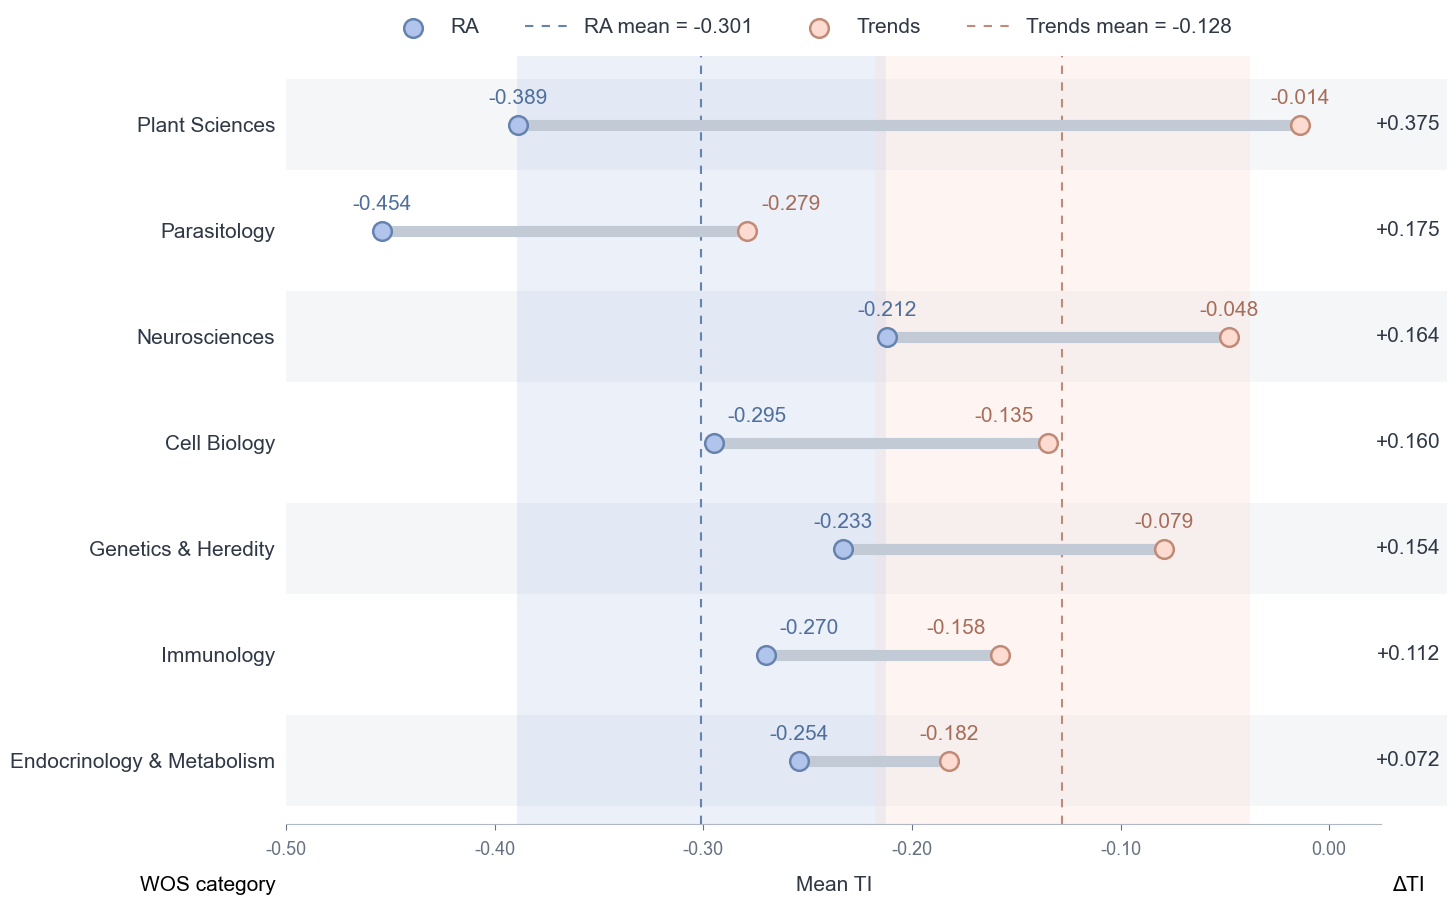

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# ==================== 数据 ====================
categories = np.array([
    "Cell Biology",
    "Endocrinology & Metabolism",
    "Genetics & Heredity",
    "Immunology",
    "Neurosciences",
    "Parasitology",
    "Plant Sciences",
])

ra = np.array([
    -0.295, -0.254, -0.233, -0.270,
    -0.212, -0.454, -0.389
])

trends = np.array([
    -0.135, -0.182, -0.079, -0.158,
    -0.048, -0.279, -0.014
])

delta = trends - ra

# 两组各自在 7 个学科上的等权均值
ra_mean = ra.mean()
ra_std = ra.std(ddof=1)

trends_mean = trends.mean()
trends_std = trends.std(ddof=1)

# 按差值从大到小排序
# 保留原顺序时，改为：order = np.arange(len(categories))
order = np.argsort(-delta)
categories = categories[order]
ra = ra[order]
trends = trends[order]
delta = delta[order]

y = np.arange(len(categories))

# ==================== 可调整参数 ====================
SHOW_ROW_BACKGROUND = True   # 交替浅灰行背景
SHOW_MEAN_LINES = True       # 两条均值竖线
SHOW_MEAN_BAND = True        # 两个均值之间的背景带
SHOW_VALUE_LABELS = True     # 两端原始数值
SAVE_FIGURE = True          # 是否保存文件

RA_COLOR = "#B1C4EB"
TRENDS_COLOR = "#FEDBD0"
RA_EDGE = "#6683B0"
TRENDS_EDGE = "#C18A76"

LINE_COLOR = "#C2CAD5"
ROW_COLOR = "#F5F6F8"
BAND_COLOR = "#DEE6EF"

# ==================== 字体与画布 ====================
plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "DejaVu Sans"],
    "font.size": 15,
    "text.color": "#303846",
    "axes.labelcolor": "#303846",
    "xtick.color": "#657080",
    "ytick.color": "#303846",
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

fig, ax = plt.subplots(figsize=(15, 12))

# 左侧留给学科名称，右侧留给差值列
fig.subplots_adjust(
    left=0.30,
    right=0.85,
    bottom=0.12,
    top=0.80
)

# ==================== 背景 ====================
# 所有着色行使用同一种浅灰色，不单独突出任何学科
if SHOW_ROW_BACKGROUND:
    for i in y:
        if i % 2 == 0:
            ax.axhspan(
                i - 0.43,
                i + 0.43,
                xmin=0,
                xmax=1.06,
                facecolor=ROW_COLOR,
                edgecolor="none",
                clip_on=False,
                zorder=0
            )

# 两条均值竖线之间的背景带
# 仅表示两组学科均值之间的范围，不表示置信区间
# ==================== 均值 ± 1 SD 背景带 ====================
if SHOW_MEAN_BAND:
    # RA：浅蓝色背景带
    ax.axvspan(
        ra_mean - ra_std,
        ra_mean + ra_std,
        facecolor=RA_COLOR,
        alpha=0.25,
        edgecolor="none",
        zorder=0.5
    )

    # Trends：浅橙色背景带
    ax.axvspan(
        trends_mean - trends_std,
        trends_mean + trends_std,
        facecolor=TRENDS_COLOR,
        alpha=0.25,
        edgecolor="none",
        zorder=0.5
    )


# ==================== 均值竖线 ====================
mean_handles = []

if SHOW_MEAN_LINES:
    ra_mean_line = ax.axvline(
        ra_mean,
        color=RA_EDGE,
        linestyle=(0, (4, 4)),
        linewidth=1.5,
        label=f"RA mean = {ra_mean:.3f}",
        zorder=1
    )

    trends_mean_line = ax.axvline(
        trends_mean,
        color=TRENDS_EDGE,
        linestyle=(0, (4, 4)),
        linewidth=1.5,
        label=f"Trends mean = {trends_mean:.3f}",
        zorder=1
    )

    mean_handles = [ra_mean_line, trends_mean_line]

# ==================== 哑铃连接线 ====================
# 每一行使用相同颜色、相同粗细
for i in y:
    ax.plot(
        [ra[i], trends[i]],
        [i, i],
        color=LINE_COLOR,
        linewidth=8,
        solid_capstyle="round",
        zorder=2
    )

# ==================== 圆形端点 ====================
ra_points = ax.scatter(
    ra, y,
    s=180,
    marker="o",
    facecolors=RA_COLOR,
    edgecolors=RA_EDGE,
    linewidths=1.8,
    label="RA",
    zorder=4
)

trends_points = ax.scatter(
    trends, y,
    s=180,
    marker="o",
    facecolors=TRENDS_COLOR,
    edgecolors=TRENDS_EDGE,
    linewidths=1.8,
    label="Trends",
    zorder=4
)

# ==================== 原始数值标签 ====================
def add_value_label(value, row, color):
    """标签放在圆点上方；靠近均值竖线时，向远离竖线的一侧偏移。"""
    offset_x = 0
    alignment = "center"

    if SHOW_MEAN_LINES:
        means = np.array([ra_mean, trends_mean])
        nearest_mean = means[np.argmin(np.abs(means - value))]

        if abs(value - nearest_mean) < 0.035:
            if value >= nearest_mean:
                offset_x = 10
                alignment = "left"
            else:
                offset_x = -10
                alignment = "right"

    ax.annotate(
        f"{value:.3f}",
        xy=(value, row),
        xytext=(offset_x, 12),
        textcoords="offset points",
        ha=alignment,
        va="bottom",
        fontsize=15,
        color=color,
        zorder=5
    )


if SHOW_VALUE_LABELS:
    for i in y:
        add_value_label(ra[i], i, "#4F6F9D")
        add_value_label(trends[i], i, "#A76D59")

# 统一控制右侧差值数字及其标题的位置
DELTA_X = 1.025

# ==================== 右侧差值列 ====================
# 所有差值使用相同样式，不加粗或突出第一行


for i in y:
    ax.text(
        DELTA_X,
        i,
        f"{delta[i]:+.3f}",
        transform=ax.get_yaxis_transform(),
        ha="center",
        va="center",
        fontsize=15,
        color="#303846",
        clip_on=False
    )
# ==================== 坐标轴 ====================
ax.set_yticks(y)
ax.set_yticklabels(categories)

# 最大差值位于最上方
ax.set_ylim(len(categories) - 0.40, -0.65)
ax.set_xlim(-0.50, 0.025)

ax.set_xlabel("Mean TI", labelpad=14)

footer_y = -0.08

ax.text(
    -0.01, footer_y,
    "WOS category",
    transform=ax.transAxes,
    ha="right",
    va="center",
    fontsize=15,
    color="#000000",
    clip_on=False
)

ax.text(
    DELTA_X, footer_y,
    "ΔTI",
    transform=ax.transAxes,
    ha="center",
    va="center",
    fontsize=15,
    color="#000000",
    clip_on=False
)

# 横轴标题与左右列标题对齐
ax.xaxis.set_label_coords(0.50, footer_y)
ax.xaxis.label.set_verticalalignment("center")

# 给底部文字留出空间
fig.subplots_adjust(
    left=0.20,      # 原来 0.30，缩小学科名称区域
    right=0.93,     # 原来 0.85，让绘图区向右扩展
    bottom=0.16,
    top=0.80
)


ax.tick_params(axis="y", length=0, pad=8)
ax.tick_params(axis="x", labelsize=13, length=4, pad=8)

ax.xaxis.set_major_locator(MultipleLocator(0.10))
ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
ax.spines["bottom"].set_color("#AEB7C3")

# ==================== 图例 ====================
if SHOW_MEAN_LINES:
    # 两列：第一列 RA 及其均值，第二列 Trends 及其均值
    legend_handles = [
        ra_points, mean_handles[0],
        trends_points, mean_handles[1]
    ]
else:
    legend_handles = [ra_points, trends_points]

ax.legend(
    handles=legend_handles,
    loc="lower center",
    bbox_to_anchor=(0.48, 1),        # 调整图例与图片正文的距离
    ncol=len(legend_handles),
    frameon=False,
    fontsize=15,
    handletextpad=0.8,
    columnspacing=2.2,
    labelspacing=1.0
)


# # ==================== 可选保存 ====================
# if SAVE_FIGURE:
#     output_dir = (
#         Path(__file__).resolve().parent
#         if "__file__" in globals()
#         else Path.cwd()
#     )

#     fig.savefig(output_dir / "ti_dumbbell.png", dpi=600, bbox_inches="tight")
#     fig.savefig(output_dir / "ti_dumbbell.pdf", bbox_inches="tight")
#     fig.savefig(output_dir / "ti_dumbbell.svg", bbox_inches="tight")

plt.show()